# Part 2 — French Nutrition Panel OCR Validation

This notebook continues from the manually reviewed Open Food Facts panel for product **241013128**. It compares EasyOCR-derived candidates with the existing manual transcription and structured gold record, while keeping OCR output, hand-entered reference text, and rule-based predictions distinct.

**Important:** this is a one-image validation fixture, not a population benchmark. EasyOCR was run on CPU after explicit user request; its detector and recognizer weights are now cached locally under `models/easyocr`. The notebook enables OCR for this reviewed image but disables future weight downloads by default. If OCR fails, it reports the failure and never fabricates detections.

## 1. Load verified image and gold transcription

Load only the existing local image and gold files. The image is validated and displayed; the text and structured labels are loaded as manual reference material.

{'project_root': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution', 'product_id': '241013128', 'image_size': (400, 253), 'manual_gold_fields': 16}


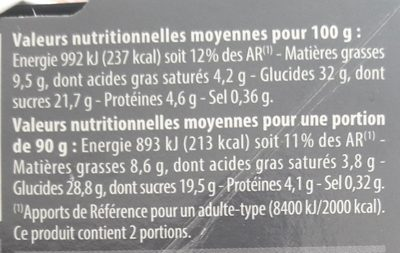

In [1]:
from __future__ import annotations

import importlib.util
import json
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import display
from PIL import Image, ImageOps

# Resolve the project root whether the notebook is launched from the repo root or part2/.
CWD = Path.cwd().resolve()
ROOT = CWD
if not (ROOT / "part2" / "entity_extraction.py").exists():
    if (ROOT.parent / "part2" / "entity_extraction.py").exists():
        ROOT = ROOT.parent
    elif (ROOT / "nutrition_extraction_solution" / "part2" / "entity_extraction.py").exists():
        ROOT = ROOT / "nutrition_extraction_solution"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

PRODUCT_ID = "241013128"
IMAGE_PATH = ROOT / "data" / "manual_samples" / f"{PRODUCT_ID}_nutrition.jpg"
GOLD_OCR_PATH = ROOT / "data" / "evaluation" / "gold_ocr.txt"
GOLD_RECORDS_PATH = ROOT / "data" / "evaluation" / "gold_records.jsonl"
REPORT_DIR = ROOT / "reports" / "part2_ocr_validation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

assert IMAGE_PATH.is_file(), f"Verified image missing: {IMAGE_PATH}"
assert GOLD_OCR_PATH.is_file(), f"Manual OCR transcription missing: {GOLD_OCR_PATH}"
assert GOLD_RECORDS_PATH.is_file(), f"Manual structured gold missing: {GOLD_RECORDS_PATH}"

manual_text = GOLD_OCR_PATH.read_text(encoding="utf-8")
gold_payloads = [json.loads(line) for line in GOLD_RECORDS_PATH.read_text(encoding="utf-8").splitlines() if line.strip()]
gold_record = next((item for item in gold_payloads if str(item.get("product_id")) == PRODUCT_ID), None)
assert gold_record is not None, f"No gold record for product {PRODUCT_ID}"

with Image.open(IMAGE_PATH) as opened:
    opened.verify()
with Image.open(IMAGE_PATH) as opened:
    verified_image = ImageOps.exif_transpose(opened).convert("RGB")

print({"project_root": str(ROOT), "product_id": PRODUCT_ID, "image_size": verified_image.size, "manual_gold_fields": len(gold_record.get("fields", []))})
display(verified_image)


## 2. Create structured nutrition record from manual gold

Normalize only the manual reference into Part 2's basis-grouped schema. This remains gold data and is not mixed with OCR predictions.

In [2]:
from part2.schemas import ExtractionResult, NutrientValue, validate_extraction_payload
from part2.normalization import normalize_unit


def normalize_gold_basis(raw_basis: str) -> str:
    value = str(raw_basis).casefold().replace(" ", "")
    if value in {"100g", "per_100g"}:
        return "per_100g"
    if value in {"100ml", "per_100ml"}:
        return "per_100ml"
    if "serv" in value or "portion" in value:
        return "per_serving"
    return "unspecified"


gold_structured = {"per_100g": {}, "per_serving": {}}
for field in gold_record.get("fields", []):
    basis = normalize_gold_basis(field.get("basis", ""))
    nutrient = str(field["nutrient"])
    gold_structured.setdefault(basis, {}).setdefault(nutrient, []).append({
        "value": float(field["value"]),
        "unit": normalize_unit(field.get("unit")),
        "raw_unit": field.get("unit"),
        "raw_text": field.get("raw_text"),
    })

gold_structured = {basis: values for basis, values in gold_structured.items() if values}
print("Manual gold, normalized by basis:")
display(pd.DataFrame([
    {"basis": basis, "nutrient": nutrient, **value}
    for basis, values in gold_structured.items()
    for nutrient, items in values.items()
    for value in items
]))
assert len(gold_record["fields"]) == 16


Manual gold, normalized by basis:


,basis,nutrient,value,unit,raw_unit,raw_text
0,per_100g,energy,992.00,kj,kJ,None
1,per_100g,energy,237.00,kcal,kcal,None
2,per_100g,fat,9.50,g,g,None
3,per_100g,saturated_fat,4.20,g,g,None
4,per_100g,carbohydrates,32.00,g,g,None
5,per_100g,sugars,21.70,g,g,None
6,per_100g,proteins,4.60,g,g,None
7,per_100g,salt,0.36,g,g,None
8,per_serving,energy,893.00,kj,kJ,None
9,per_serving,energy,213.00,kcal,kcal,None


EasyOCR is opt-in in general; for this reviewed image the user requested a real CPU inference run. French and English were enabled, and the required detector/recognizer weights were downloaded once and cached in `models/easyocr`. This cell keeps `download_enabled=False` now so future runs reuse the local weights rather than downloading them again.

In [13]:
from part2.config import OCRConfig, PreprocessingConfig
from part2.ocr import run_easyocr

# OCR is enabled for this reviewed image. Weights were downloaded once after approval
# and are cached locally, so do not download them again on subsequent runs.
RUN_EASYOCR = True
ALLOW_EASYOCR_WEIGHT_DOWNLOAD = False
OCR_LANGUAGES = ("fr", "en")

easyocr_available = importlib.util.find_spec("easyocr") is not None
print({
    "easyocr_package_available": easyocr_available,
    "gpu": False,
    "run_enabled": RUN_EASYOCR,
    "weight_download_enabled": ALLOW_EASYOCR_WEIGHT_DOWNLOAD,
    "languages": OCR_LANGUAGES,
})

ocr_config = OCRConfig(
    languages=OCR_LANGUAGES,
    gpu=False,
    allow_model_downloads=ALLOW_EASYOCR_WEIGHT_DOWNLOAD,
    model_storage_directory=ROOT / "models" / "easyocr",
    cache_directory=ROOT / "data" / "part2_cache" / "ocr",
    preprocessing=PreprocessingConfig(max_side=2000, contrast=1.15, grayscale=False),
)
if RUN_EASYOCR:
    ocr_result = run_easyocr(IMAGE_PATH, ocr_config)
else:
    ocr_result = None
    print("OCR skipped by configuration.")

if ocr_result is not None:
    print({"error": ocr_result.error, "detection_count": len(ocr_result.detections), "elapsed_seconds": ocr_result.elapsed_seconds, "from_cache": ocr_result.from_cache})
    if ocr_result.error:
        print("No OCR output was produced:", ocr_result.error)
    else:
        display(pd.DataFrame([detection.to_dict() for detection in ocr_result.detections]))


{'easyocr_package_available': True, 'gpu': False, 'run_enabled': True, 'weight_download_enabled': False, 'languages': ('fr', 'en')}
{'error': None, 'detection_count': 11, 'elapsed_seconds': 1.7837325999280438, 'from_cache': True}


,text,bbox,confidence,reading_order
0,Valeurs nutritionnelles moyennes pour 100 9:,"[[8, 20], [366, 20], [366, 50], [8, 50]]",0.675183,0
1,Energie 992k/ (237 kcal) soit 12% des ARI _ Ma...,"[[8, 42], [390, 42], [390, 72], [8, 72]]",0.304988,1
2,"9,59, dont acides gras saturés 4,2 9 - Glucide...","[[8, 62], [390, 62], [390, 94], [8, 94]]",0.463133,2
3,"sucres 21,7g - Proteines 4,69 -Sel 0,36g","[[10, 84], [276, 84], [276, 114], [10, 114]]",0.639606,3
4,Valeurs nutritionnelles moyennes pour une portion,"[[8, 104], [390, 104], [390, 136], [8, 136]]",0.939249,4
5,de 90 g,"[[8, 134], [70, 134], [70, 160], [8, 160]]",0.493663,5
6,"Energie 893 kJ (213 kcal) soit 11% des AR(""","[[76, 126], [380, 126], [380, 158], [76, 158]]",0.379380,6
7,"Matières grasses 8,6 9, dont acides gras satur...","[[8, 150], [380, 150], [380, 180], [8, 180]]",0.468417,7
8,"Glucides 28,89,dont suces 19,59-Proteines 4,19...","[[8, 170], [388, 170], [388, 202], [8, 202]]",0.481005,8
9,@Apports de Référence pour un adulte-type (840...,"[[5, 193], [389, 193], [389, 230], [5, 230]]",0.479027,9


## 4. Parse OCR tokens and bounding boxes

The EasyOCR adapter retains each detection's text, polygon, confidence, and reading-order index. Show the real results and draw their boxes only when OCR succeeded; otherwise the next sections run as empty predictions and produce no false matches.

,order,text,bbox_polygon,confidence_raw,center_x,center_y
0,0,Valeurs nutritionnelles moyennes pour 100 9:,"[[8, 20], [366, 20], [366, 50], [8, 50]]",0.675183,187.0,35.0
1,1,Energie 992k/ (237 kcal) soit 12% des ARI _ Ma...,"[[8, 42], [390, 42], [390, 72], [8, 72]]",0.304988,199.0,57.0
2,2,"9,59, dont acides gras saturés 4,2 9 - Glucide...","[[8, 62], [390, 62], [390, 94], [8, 94]]",0.463133,199.0,78.0
3,3,"sucres 21,7g - Proteines 4,69 -Sel 0,36g","[[10, 84], [276, 84], [276, 114], [10, 114]]",0.639606,143.0,99.0
4,4,Valeurs nutritionnelles moyennes pour une portion,"[[8, 104], [390, 104], [390, 136], [8, 136]]",0.939249,199.0,120.0
5,5,de 90 g,"[[8, 134], [70, 134], [70, 160], [8, 160]]",0.493663,39.0,147.0
6,6,"Energie 893 kJ (213 kcal) soit 11% des AR(""","[[76, 126], [380, 126], [380, 158], [76, 158]]",0.379380,228.0,142.0
7,7,"Matières grasses 8,6 9, dont acides gras satur...","[[8, 150], [380, 150], [380, 180], [8, 180]]",0.468417,194.0,165.0
8,8,"Glucides 28,89,dont suces 19,59-Proteines 4,19...","[[8, 170], [388, 170], [388, 202], [8, 202]]",0.481005,198.0,186.0
9,9,@Apports de Référence pour un adulte-type (840...,"[[5, 193], [389, 193], [389, 230], [5, 230]]",0.479027,197.0,211.5


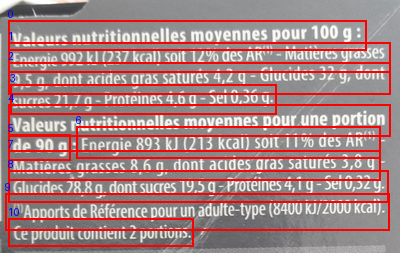

OCR text preview (actual recognizer output only):
Valeurs nutritionnelles moyennes pour 100 9: Energie 992k/ (237 kcal) soit 12% des ARI _ Matières grasses 9,59, dont acides gras saturés 4,2 9 - Glucides 32 9, dont sucres 21,7g - Proteines 4,69 -Sel 0,36g Valeurs nutritionnelles moyennes pour une portion de 90 g Energie 893 kJ (213 kcal) soit 11% des AR(" Matières grasses 8,6 9, dont acides gras saturés 3,8 9 Glucides 28,89,dont suces 19,59-Proteines 4,19-Sel0,32g @Apports de Référence pour un adulte-type (8400 kJ/2000 kcal) . (e produit contient 2 portions .


In [14]:
import matplotlib.pyplot as plt
from PIL import ImageDraw

ocr_detections = ocr_result.detections if ocr_result is not None and not ocr_result.error else []
ocr_text = " ".join(detection.text for detection in ocr_detections)

def detection_table(detections):
    return pd.DataFrame([
        {
            "order": item.reading_order,
            "text": item.text,
            "bbox_polygon": item.bbox,
            "confidence_raw": item.confidence,
            "center_x": sum(point[0] for point in item.bbox) / len(item.bbox),
            "center_y": sum(point[1] for point in item.bbox) / len(item.bbox),
        }
        for item in detections
    ])

if ocr_detections:
    tokens_df = detection_table(ocr_detections)
    display(tokens_df)
    preview = verified_image.copy()
    draw = ImageDraw.Draw(preview)
    for item in ocr_detections:
        draw.polygon([tuple(point) for point in item.bbox], outline="red", width=2)
        x0, y0 = item.bbox[0]
        draw.text((x0, max(0, y0 - 12)), str(item.reading_order), fill="blue")
    display(preview)
else:
    tokens_df = pd.DataFrame(columns=["order", "text", "bbox_polygon", "confidence_raw", "center_x", "center_y"])
    print("No OCR tokens available to parse or visualize.")

print("OCR text preview (actual recognizer output only):")
print(ocr_text if ocr_text else "<no OCR output>")

## 5. Tag nutrient, value, and unit entities

Use the implemented French/English aliases and conservative number/unit parser. Percentages are retained as detected text; they are not treated as nutrient quantity values. OCR scores remain raw recognizer scores, not calibrated extraction confidence.

In [15]:
from part2.entity_extraction import match_nutrient_name
from part2.normalization import normalize_text, nutrition_basis, parse_value_unit

entity_rows = []
for detection in ocr_detections:
    nutrient_match = match_nutrient_name(detection.text)
    parsed = parse_value_unit(detection.text)
    basis = nutrition_basis(detection.text)
    normalized = normalize_text(detection.text)
    if nutrient_match:
        entity_type = "NUTRIENT"
        canonical = nutrient_match[0]
    elif parsed is not None:
        entity_type = "VALUE"
        canonical = f"{parsed.value:g} {parsed.unit or ''}".strip()
    elif basis:
        entity_type = "BASIS"
        canonical = basis
    elif "%" in detection.text:
        entity_type = "PERCENTAGE"
        canonical = detection.text.strip()
    else:
        entity_type = "O"
        canonical = None
    entity_rows.append({
        "order": detection.reading_order,
        "text": detection.text,
        "normalized_text": normalized,
        "entity_type": entity_type,
        "canonical": canonical,
        "bbox": detection.bbox,
        "ocr_confidence_raw": detection.confidence,
    })

tagged_df = pd.DataFrame(entity_rows)
display(tagged_df if not tagged_df.empty else pd.DataFrame(columns=["order", "text", "entity_type", "canonical", "bbox", "ocr_confidence_raw"]))
print("French aliases are explicit in part2.entity_extraction.NUTRIENT_ALIASES; numeric/unit parsing is in part2.normalization.")

,order,text,normalized_text,entity_type,canonical,bbox,ocr_confidence_raw
0,0,Valeurs nutritionnelles moyennes pour 100 9:,valeurs nutritionnelles moyennes pour 100 9:,VALUE,1009,"[[8, 20], [366, 20], [366, 50], [8, 50]]",0.675183
1,1,Energie 992k/ (237 kcal) soit 12% des ARI _ Ma...,energie 992k/ (237 kcal) soit 12% des ari _ ma...,NUTRIENT,energy,"[[8, 42], [390, 42], [390, 72], [8, 72]]",0.304988
2,2,"9,59, dont acides gras saturés 4,2 9 - Glucide...","9,59, dont acides gras satures 4,2 9 - glucide...",O,None,"[[8, 62], [390, 62], [390, 94], [8, 94]]",0.463133
3,3,"sucres 21,7g - Proteines 4,69 -Sel 0,36g","sucres 21,7g - proteines 4,69 -sel 0,36g",NUTRIENT,sugars,"[[10, 84], [276, 84], [276, 114], [10, 114]]",0.639606
4,4,Valeurs nutritionnelles moyennes pour une portion,valeurs nutritionnelles moyennes pour une portion,BASIS,per_serving,"[[8, 104], [390, 104], [390, 136], [8, 136]]",0.939249
5,5,de 90 g,de 90 g,VALUE,90 g,"[[8, 134], [70, 134], [70, 160], [8, 160]]",0.493663
6,6,"Energie 893 kJ (213 kcal) soit 11% des AR(""","energie 893 kj (213 kcal) soit 11% des ar(""",NUTRIENT,energy,"[[76, 126], [380, 126], [380, 158], [76, 158]]",0.379380
7,7,"Matières grasses 8,6 9, dont acides gras satur...","matieres grasses 8,6 9, dont acides gras satur...",NUTRIENT,fat,"[[8, 150], [380, 150], [380, 180], [8, 180]]",0.468417
8,8,"Glucides 28,89,dont suces 19,59-Proteines 4,19...","glucides 28,89,dont suces 19,59-proteines 4,19...",NUTRIENT,carbohydrates,"[[8, 170], [388, 170], [388, 202], [8, 202]]",0.481005
9,9,@Apports de Référence pour un adulte-type (840...,@apports de reference pour un adulte-type (840...,VALUE,8400 kj,"[[5, 193], [389, 193], [389, 230], [5, 230]]",0.479027


French aliases are explicit in part2.entity_extraction.NUTRIENT_ALIASES; numeric/unit parsing is in part2.normalization.


## 6. Associate rows by basis and visual position

The rule baseline groups detections by y-position, then uses their horizontal position and basis anchors to associate candidates. Inspect row reconstructions before accepting results. Ambiguous values, missing units, or uncertain basis columns remain unresolved.

In [18]:
import importlib
import part2.entity_extraction as entity_extraction_module
entity_extraction_module = importlib.reload(entity_extraction_module)
from part2.entity_extraction import _row_groups, extract_nutrients

visual_rows = _row_groups(ocr_detections)
row_table = pd.DataFrame([
    {
        "visual_row": row_index,
        "center_y": round(sum(sum(point[1] for point in item.bbox) / len(item.bbox) for item in row) / len(row), 1),
        "tokens_left_to_right": " | ".join(item.text for item in row),
    }
    for row_index, row in enumerate(visual_rows)
])
display(row_table if not row_table.empty else pd.DataFrame(columns=["visual_row", "center_y", "tokens_left_to_right"]))

if ocr_result is not None and not ocr_result.error:
    prediction = extract_nutrients(
        ocr_detections,
        barcode=PRODUCT_ID,
        image_path=str(IMAGE_PATH),
        image_width=verified_image.width,
    )
    prediction.ocr_error = None
    prediction.processing_time_seconds = ocr_result.elapsed_seconds
    prediction_payload = prediction.to_dict()
    validate_extraction_payload(prediction_payload)
else:
    prediction = None
    prediction_payload = {
        "barcode": PRODUCT_ID,
        "image_path": str(IMAGE_PATH),
        "nutrition_basis": None,
        "nutrients": {},
        "unresolved_fields": [],
        "warnings": ["No OCR-derived prediction is available; OCR was skipped or failed."],
        "ocr_error": None if ocr_result is None else ocr_result.error,
        "method": "easyocr+spatial-rules",
    }

print("Rule-based extraction output (empty if OCR has not run):")
print(json.dumps(prediction_payload, indent=2, ensure_ascii=False))

,visual_row,center_y,tokens_left_to_right
0,0,35.0,Valeurs nutritionnelles moyennes pour 100 9:
1,1,57.0,Energie 992k/ (237 kcal) soit 12% des ARI _ Ma...
2,2,78.0,"9,59, dont acides gras saturés 4,2 9 - Glucide..."
3,3,99.0,"sucres 21,7g - Proteines 4,69 -Sel 0,36g"
4,4,120.0,Valeurs nutritionnelles moyennes pour une portion
5,5,144.5,de 90 g | Energie 893 kJ (213 kcal) soit 11% d...
6,6,165.0,"Matières grasses 8,6 9, dont acides gras satur..."
7,7,186.0,"Glucides 28,89,dont suces 19,59-Proteines 4,19..."
8,8,211.5,@Apports de Référence pour un adulte-type (840...
9,9,232.0,(e produit contient 2 portions .


Rule-based extraction output (empty if OCR has not run):
{
  "barcode": "241013128",
  "image_path": "C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution\\data\\manual_samples\\241013128_nutrition.jpg",
  "nutrition_basis": "per_serving",
  "nutrients": {
    "unspecified": {
      "sugars": [
        {
          "value": 21.7,
          "unit": "g",
          "basis": "unspecified",
          "raw_text": "21,7g",
          "ocr_confidence": 0.6396063083234779,
          "normalized_value": 21.7,
          "normalized_unit": "g"
        }
      ]
    },
    "per_serving": {
      "energy_kj": [
        {
          "value": 893.0,
          "unit": "kj",
          "basis": "per_serving",
          "raw_text": "893 kJ",
          "ocr_confidence": 0.37937989078940126,
          "normalized_value": 213.4321223709369,
          "normalized_unit": "kcal"
        }
      ]
    }
  },
  "unresolved_fields": [
    {
      "nutrient": "energy",
      "rea

## 7. Compare extracted fields to gold labels

Compare fields separately by nutrient and basis. Exact value/unit matches and a documented numeric tolerance are both reported. OCR text errors, missing fields, value/unit differences, and basis assignment are kept distinct. With OCR skipped or failed, comparisons are marked unavailable rather than scored as zero-performing extraction.

In [19]:
from collections import defaultdict
from part2.evaluation import cer, wer
from part2.normalization import canonicalize
import re


def basis_key(raw_basis: str) -> str:
    value = str(raw_basis).casefold().replace(" ", "")
    if value in {"100g", "per_100g"}:
        return "per_100g"
    if "serv" in value or "portion" in value:
        return "per_serving"
    if value in {"100ml", "per_100ml"}:
        return "per_100ml"
    return "unspecified"


def canonical_nutrient(raw_nutrient: str) -> str:
    # The rule extractor keeps energy unit in its entity key; gold uses energy + unit.
    if raw_nutrient in {"energy_kj", "energy_kcal"}:
        return "energy"
    return raw_nutrient


def normalized_items(record: dict, *, prediction_side: bool) -> list[dict]:
    items = []
    if prediction_side:
        for basis, nutrient_map in record.get("nutrients", {}).items():
            for nutrient, values in nutrient_map.items():
                values = values if isinstance(values, list) else [values]
                for value in values:
                    numeric, unit = canonicalize(float(value["value"]), value.get("unit"))
                    items.append({"basis": basis_key(basis), "nutrient": canonical_nutrient(str(nutrient)), "value": numeric, "unit": unit, "raw_unit": value.get("unit"), "raw_text": value.get("raw_text")})
    else:
        for field in record.get("fields", []):
            numeric, unit = canonicalize(float(field["value"]), field.get("unit"))
            items.append({"basis": basis_key(field.get("basis", "")), "nutrient": canonical_nutrient(str(field["nutrient"])), "value": numeric, "unit": unit, "raw_unit": field.get("unit"), "raw_text": field.get("raw_text")})
    return items


gold_items = normalized_items(gold_record, prediction_side=False)
pred_items = normalized_items(prediction_payload, prediction_side=True)
NUMERIC_TOLERANCE = 0.05  # display-rounding tolerance after compatible-unit normalization
ocr_success = ocr_result is not None and not ocr_result.error

# Match by nutrient and compatible normalized unit, ignoring basis during matching
# so wrong-basis assignments are exposed rather than hidden as unrelated fields.
pairs = []
unused_gold = set(range(len(gold_items)))
unused_pred = set(range(len(pred_items)))
possible_pairs = []
for gi, gold in enumerate(gold_items):
    for pi, pred in enumerate(pred_items):
        if gold["nutrient"] == pred["nutrient"] and gold["unit"] == pred["unit"]:
            possible_pairs.append((abs(gold["value"] - pred["value"]), gi, pi))
for delta, gi, pi in sorted(possible_pairs):
    if gi in unused_gold and pi in unused_pred:
        pairs.append((gi, pi, delta))
        unused_gold.remove(gi)
        unused_pred.remove(pi)

comparison_rows = []
for gi, pi, delta in pairs:
    gold, pred = gold_items[gi], pred_items[pi]
    basis_match = gold["basis"] == pred["basis"]
    value_match = delta <= NUMERIC_TOLERANCE
    exact_original_unit_match = gold["raw_unit"].casefold() == pred["raw_unit"].casefold() if gold["raw_unit"] and pred["raw_unit"] else gold["unit"] == pred["unit"]
    exact = basis_match and value_match and exact_original_unit_match
    status = "exact_match" if exact else ("basis_mismatch" if not basis_match else ("within_tolerance" if value_match else "value_mismatch"))
    comparison_rows.append({"nutrient": gold["nutrient"], "gold_basis": gold["basis"], "predicted_basis": pred["basis"], "basis_match": basis_match, "gold_value": gold["value"], "gold_unit_canonical": gold["unit"], "gold_unit_original": gold["raw_unit"], "predicted_value": pred["value"], "predicted_unit_canonical": pred["unit"], "predicted_unit_original": pred["raw_unit"], "absolute_difference_canonical_units": delta, "value_within_tolerance": value_match, "exact_original_unit_match": exact_original_unit_match, "exact_nutrient_value_unit_basis_match": exact, "status": status})
for gi in sorted(unused_gold):
    gold = gold_items[gi]
    comparison_rows.append({"nutrient": gold["nutrient"], "gold_basis": gold["basis"], "predicted_basis": None, "basis_match": False, "gold_value": gold["value"], "gold_unit_canonical": gold["unit"], "gold_unit_original": gold["raw_unit"], "predicted_value": None, "predicted_unit_canonical": None, "predicted_unit_original": None, "absolute_difference_canonical_units": None, "value_within_tolerance": False if ocr_success else None, "exact_original_unit_match": False if ocr_success else None, "exact_nutrient_value_unit_basis_match": False if ocr_success else None, "status": "missing_prediction" if ocr_success else "not_evaluated_ocr_skipped_or_failed"})
for pi in sorted(unused_pred):
    pred = pred_items[pi]
    comparison_rows.append({"nutrient": pred["nutrient"], "gold_basis": None, "predicted_basis": pred["basis"], "basis_match": False, "gold_value": None, "gold_unit_canonical": None, "gold_unit_original": None, "predicted_value": pred["value"], "predicted_unit_canonical": pred["unit"], "predicted_unit_original": pred["raw_unit"], "absolute_difference_canonical_units": None, "value_within_tolerance": False if ocr_success else None, "exact_original_unit_match": False if ocr_success else None, "exact_nutrient_value_unit_basis_match": False if ocr_success else None, "status": "unexpected_prediction" if ocr_success else "not_evaluated_ocr_skipped_or_failed"})
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

if ocr_success:
    text_cer = cer(manual_text, ocr_text)
    text_wer = wer(manual_text, ocr_text)
    text_metrics_status = "measured against one manually transcribed reference"
else:
    text_cer = text_wer = None
    text_metrics_status = "not calculated: no successful OCR output"

manual_percentages = re.findall(r"\d+(?:[,.]\d+)?\s*%", manual_text)
ocr_percentages = re.findall(r"\d+(?:[,.]\d+)?\s*%", ocr_text) if ocr_text else []
matched_basis_count = sum(bool(row["basis_match"]) for row in comparison_rows if row["gold_basis"] is not None and row["predicted_basis"] is not None)
basis_support_count = sum(row["gold_basis"] is not None and row["predicted_basis"] is not None for row in comparison_rows)
basis_assignment_accuracy = matched_basis_count / basis_support_count if ocr_success and basis_support_count else (0.0 if ocr_success else None)
print({"ocr_status": text_metrics_status, "cer": text_cer, "wer": text_wer, "manual_reference_percentages": manual_percentages, "ocr_detected_percentages": ocr_percentages, "basis_assignment_accuracy": basis_assignment_accuracy, "basis_support": basis_support_count if ocr_success else None})

,nutrient,gold_basis,predicted_basis,basis_match,gold_value,gold_unit_canonical,gold_unit_original,predicted_value,predicted_unit_canonical,predicted_unit_original,absolute_difference_canonical_units,value_within_tolerance,exact_original_unit_match,exact_nutrient_value_unit_basis_match,status
0,sugars,per_100g,unspecified,False,21.700000,g,g,21.700000,g,g,0.0,True,True,False,basis_mismatch
1,energy,per_serving,per_serving,True,213.432122,kcal,kJ,213.432122,kcal,kj,0.0,True,True,True,exact_match
2,energy,per_100g,None,False,237.093690,kcal,kJ,NaN,None,None,NaN,False,False,False,missing_prediction
3,energy,per_100g,None,False,237.000000,kcal,kcal,NaN,None,None,NaN,False,False,False,missing_prediction
4,fat,per_100g,None,False,9.500000,g,g,NaN,None,None,NaN,False,False,False,missing_prediction
5,saturated_fat,per_100g,None,False,4.200000,g,g,NaN,None,None,NaN,False,False,False,missing_prediction
6,carbohydrates,per_100g,None,False,32.000000,g,g,NaN,None,None,NaN,False,False,False,missing_prediction
7,proteins,per_100g,None,False,4.600000,g,g,NaN,None,None,NaN,False,False,False,missing_prediction
8,salt,per_100g,None,False,0.360000,g,g,NaN,None,None,NaN,False,False,False,missing_prediction
9,energy,per_serving,None,False,213.000000,kcal,kcal,NaN,None,None,NaN,False,False,False,missing_prediction


{'ocr_status': 'measured against one manually transcribed reference', 'cer': 0.09908256880733946, 'wer': 0.4423076923076923, 'manual_reference_percentages': ['12%', '11%'], 'ocr_detected_percentages': ['12%', '11%'], 'basis_assignment_accuracy': 0.5, 'basis_support': 2}


## 8. Compute OCR and extraction diagnostics

This one-image analysis is a validation fixture, not a population performance estimate. CER/WER are only calculated when EasyOCR actually ran successfully. Field metrics distinguish present nutrient+basis keys, exact value/unit matches, numeric error for unit-compatible matches, unit accuracy, and basis assignment.

In [20]:
ocr_success = ocr_result is not None and not ocr_result.error
matched_rows = comparison_df[
    comparison_df["gold_basis"].notna() & comparison_df["predicted_basis"].notna()
] if not comparison_df.empty else pd.DataFrame()
exact_tuple_mask = matched_rows["exact_nutrient_value_unit_basis_match"].fillna(False) if not matched_rows.empty else pd.Series(dtype=bool)
exact_tuple_tp = int(exact_tuple_mask.sum())
prediction_count = len(pred_items)
gold_count = len(gold_items)
field_fp = prediction_count - exact_tuple_tp
field_fn = gold_count - exact_tuple_tp
field_precision = exact_tuple_tp / prediction_count if prediction_count else 0.0
field_recall = exact_tuple_tp / gold_count if gold_count else 0.0
field_f1 = 2 * field_precision * field_recall / (field_precision + field_recall) if field_precision + field_recall else 0.0

unit_support = int(len(matched_rows))
unit_matches = int(matched_rows["exact_original_unit_match"].fillna(False).sum()) if unit_support else 0
value_unit_matches = int(matched_rows["value_within_tolerance"].fillna(False).sum()) if unit_support else 0
basis_support = int(len(matched_rows))
basis_matches = int(matched_rows["basis_match"].fillna(False).sum()) if basis_support else 0
numeric_errors = matched_rows["absolute_difference_canonical_units"].dropna().astype(float).tolist() if unit_support else []
record_exact_match = bool(
    ocr_success
    and exact_tuple_tp == gold_count
    and prediction_count == gold_count
) if ocr_success else None

metrics = {
    "reference_product_id": PRODUCT_ID,
    "reference_images": 1,
    "reference_fields": gold_count,
    "predicted_fields": prediction_count if ocr_success else None,
    "ocr_status": "not_run" if ocr_result is None else ("failed" if ocr_result.error else "success"),
    "cer": text_cer,
    "wer": text_wer,
    "exact_tuple_field_precision": field_precision if ocr_success else None,
    "exact_tuple_field_recall": field_recall if ocr_success else None,
    "exact_tuple_field_f1": field_f1 if ocr_success else None,
    "exact_tuple_tp": exact_tuple_tp if ocr_success else None,
    "exact_tuple_fp": field_fp if ocr_success else None,
    "exact_tuple_fn": field_fn if ocr_success else None,
    "value_unit_within_tolerance_count": value_unit_matches if ocr_success else None,
    "value_unit_within_tolerance_accuracy_on_matched_pairs": value_unit_matches / unit_support if unit_support and ocr_success else (0.0 if ocr_success else None),
    "unit_accuracy_on_matched_pairs": unit_matches / unit_support if unit_support and ocr_success else (0.0 if ocr_success else None),
    "unit_support": unit_support if ocr_success else None,
    "basis_accuracy_on_matched_pairs": basis_matches / basis_support if basis_support and ocr_success else (0.0 if ocr_success else None),
    "basis_support": basis_support if ocr_success else None,
    "numeric_mae_canonical_units_on_matched_pairs": sum(numeric_errors) / len(numeric_errors) if numeric_errors else None,
    "numeric_mae_support": len(numeric_errors) if ocr_success else None,
    "record_exact_match": record_exact_match,
    "processing_time_seconds": None if ocr_result is None else ocr_result.elapsed_seconds,
    "note": "single manually reviewed image; not aggregate model performance; exact tuple requires nutrient, basis, compatible value, and original unit match",
}
print(json.dumps(metrics, indent=2, ensure_ascii=False))

{
  "reference_product_id": "241013128",
  "reference_images": 1,
  "reference_fields": 16,
  "predicted_fields": 2,
  "ocr_status": "success",
  "cer": 0.09908256880733946,
  "wer": 0.4423076923076923,
  "exact_tuple_field_precision": 0.5,
  "exact_tuple_field_recall": 0.0625,
  "exact_tuple_field_f1": 0.1111111111111111,
  "exact_tuple_tp": 1,
  "exact_tuple_fp": 1,
  "exact_tuple_fn": 15,
  "value_unit_within_tolerance_count": 2,
  "value_unit_within_tolerance_accuracy_on_matched_pairs": 1.0,
  "unit_accuracy_on_matched_pairs": 1.0,
  "unit_support": 2,
  "basis_accuracy_on_matched_pairs": 0.5,
  "basis_support": 2,
  "numeric_mae_canonical_units_on_matched_pairs": 0.0,
  "numeric_mae_support": 2,
  "record_exact_match": false,
  "processing_time_seconds": 1.7837325999280438,
  "note": "single manually reviewed image; not aggregate model performance; exact tuple requires nutrient, basis, compatible value, and original unit match"
}


## 9. Save evaluation outputs and failure logs

Export OCR detections, the rule-based structured prediction, field comparison, metric summary, and a categorized failure-review CSV under `reports/part2_ocr_validation/`. Manual gold is copied as reference provenance; OCR predictions are never substituted for it.

In [21]:
def plain_table(frame: pd.DataFrame) -> str:
    # Avoid pandas' optional tabulate dependency in a fresh notebook kernel.
    return frame.to_string(index=False) if not frame.empty else "(no rows)"

ocr_payload = {
    "product_id": PRODUCT_ID,
    "source_image": str(IMAGE_PATH.relative_to(ROOT)).replace("\\", "/"),
    "manual_reference_text": manual_text,
    "ocr_status": metrics["ocr_status"],
    "ocr_error": None if ocr_result is None else ocr_result.error,
    "detections": [] if ocr_result is None else [item.to_dict() for item in ocr_result.detections],
    "ocr_text": ocr_text,
}

(REPORT_DIR / "ocr_tokens_and_text.json").write_text(json.dumps(ocr_payload, ensure_ascii=False, indent=2), encoding="utf-8")
(REPORT_DIR / "manual_gold_record.json").write_text(json.dumps(gold_record, ensure_ascii=False, indent=2), encoding="utf-8")
(REPORT_DIR / "rule_extraction_prediction.json").write_text(json.dumps(prediction_payload, ensure_ascii=False, indent=2), encoding="utf-8")
comparison_df.to_csv(REPORT_DIR / "gold_prediction_comparison.csv", index=False)
(REPORT_DIR / "metrics_summary.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")

failure_rows = []
if ocr_success:
    for row in comparison_rows:
        if row["status"] != "exact_match":
            category = {
                "missing_prediction": "missed_nutrient_or_value",
                "unexpected_prediction": "unexpected_candidate",
                "unit_mismatch": "unit_parsing",
                "value_mismatch": "decimal_or_value_error",
                "within_tolerance": "rounding_difference",
                "basis_mismatch": "serving_vs_100g_or_basis_assignment",
            }.get(row["status"], "review")
            gold_display = f"{row.get('gold_value')} {row.get('gold_unit_original')} @ {row.get('gold_basis')}"
            prediction_display = f"{row.get('predicted_value')} {row.get('predicted_unit_original')} @ {row.get('predicted_basis')}"
            failure_rows.append({
                "product_id": PRODUCT_ID,
                "image_path": str(IMAGE_PATH.relative_to(ROOT)).replace("\\", "/"),
                "failure_type": category,
                "basis": f"gold={row.get('gold_basis')}; predicted={row.get('predicted_basis')}",
                "nutrient": row.get("nutrient", ""),
                "gold": gold_display,
                "prediction": prediction_display,
                "root_cause": row["status"],
                "severity": "review",
                "action": "Inspect OCR text, units, row association, and serving-basis column.",
            })
else:
    failure_rows.append({
        "product_id": PRODUCT_ID,
        "image_path": str(IMAGE_PATH.relative_to(ROOT)).replace("\\", "/"),
        "failure_type": "ocr_unavailable",
        "basis": "",
        "nutrient": "",
        "gold": "manual reference available",
        "prediction": "no OCR-derived fields",
        "root_cause": "OCR skipped or failed; no model metric calculated",
        "severity": "blocker",
        "action": "Install EasyOCR and explicitly enable this cell; ensure weights are cached or authorize their download.",
    })

failure_columns = ["product_id", "image_path", "failure_type", "basis", "nutrient", "gold", "prediction", "root_cause", "severity", "action"]
failures_df = pd.DataFrame(failure_rows, columns=failure_columns)
failures_df.to_csv(REPORT_DIR / "failure_analysis.csv", index=False)

report_lines = [
    "# Manual French Nutrition Panel — OCR Validation Summary",
    "",
    f"- Product: `{PRODUCT_ID}`",
    f"- Image: `{IMAGE_PATH.relative_to(ROOT).as_posix()}` ({verified_image.width}×{verified_image.height})",
    f"- OCR status: `{metrics['ocr_status']}`",
    f"- OCR detections: {len(ocr_detections)}",
    f"- Manual gold fields: {len(gold_record.get('fields', []))}",
    f"- Exact nutrient-value-unit-basis matches: {metrics['exact_tuple_tp']}",
    f"- CER/WER: {metrics['cer']} / {metrics['wer']}",
    "",
    "This is a one-image manual-validation fixture, not aggregate model performance. OCR ran with CPU EasyOCR using French and English. Its detector recognized long text lines and made visible character errors; the rule baseline therefore leaves many fields unresolved. No model-performance claim is made from one image.",
    "",
    "## Field comparison",
    "",
    "```text",
    plain_table(comparison_df),
    "```",
    "",
    "## Failure review",
    "",
    "```text",
    plain_table(failures_df),
    "```",
    "",
    "## Provenance and interpretation",
    "",
    "The reference transcription and 16 structured nutrient entries were manually reviewed earlier and loaded from the project evaluation files. EasyOCR output is kept separate. OCR confidence is a recognizer score, not calibrated field-association confidence. No OCR-to-BIO token-index comparison is made.",
]
(REPORT_DIR / "review_summary.md").write_text(chr(10).join(report_lines), encoding="utf-8")

print("Saved reproducible review artifacts to:", REPORT_DIR)
for path in sorted(REPORT_DIR.iterdir()):
    print(" -", path.name)
print("Metric status:", metrics["ocr_status"], "| measured OCR accuracy:", metrics["cer"] is not None)


Saved reproducible review artifacts to: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\part2_ocr_validation
 - failure_analysis.csv
 - gold_prediction_comparison.csv
 - manual_gold_record.json
 - metrics_summary.json
 - ocr_tokens_and_text.json
 - review_summary.md
 - rule_extraction_prediction.json
Metric status: success | measured OCR accuracy: True
